# Principal Component Analysis (PCA)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from pandas.plotting import scatter_matrix
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

## Flowers

We have 150 flowers, each described by four measurements:

- Sepal length and width
- Petal length and width

Our goal is to predict one of three species: `setosa`, `versicolor`, or `virginica`.

The measurements are our `features` (inputs, `X`); the species is our `label` (what we want to predict, `y`).

In [ ]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
names = iris.target_names

print(f'{len(X)} flowers  |  {X.shape[1]} input features  |  {len(names)} species')
X.head()

150 flowers  |  4 input features  |  3 species


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Plotting Data
Let's visualize the data to better grasp it. As four features are difficult to show in a simple plot, we plot two features against one another. 
You can change the features, as you want to experiment and view different combinations.

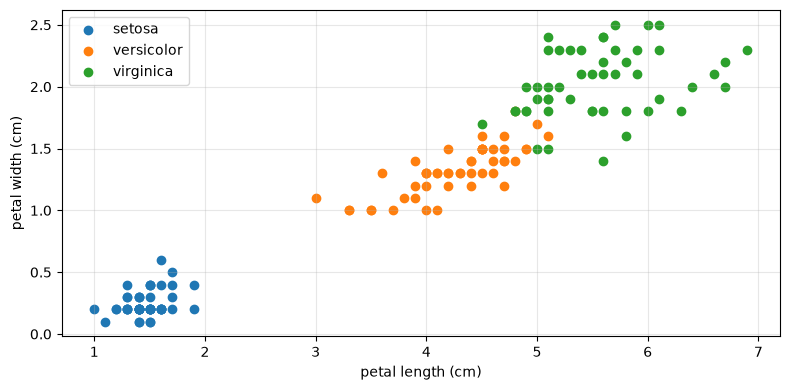

In [ ]:
feature1 = 'petal length (cm)'
feature2 = 'petal width (cm)'

fig, ax = plt.subplots(figsize=(8, 4))
for i, species in enumerate(names):
    mask = (y == i)
    ax.scatter(X.loc[mask, feature1], X.loc[mask, feature2], label=species)
ax.set(xlabel=feature1, ylabel=feature2)
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

### Plotting all feature combinations
Instead of selecting two features at a time, we can use `scatter_matrix` to plot every feature against every other feature in a grid.

On the diagonal, each feature would be plotted against itself. We use a `histogram` there instead: the values are grouped into ranges, and the height of each bar shows how many flowers fall within that range. These histograms combine all three species.

The scatter plots are repeated on either side of the diagonal, with the axes swapped. We can use this grid to see which pairs of features separate the species more clearly and which features appear to vary together.

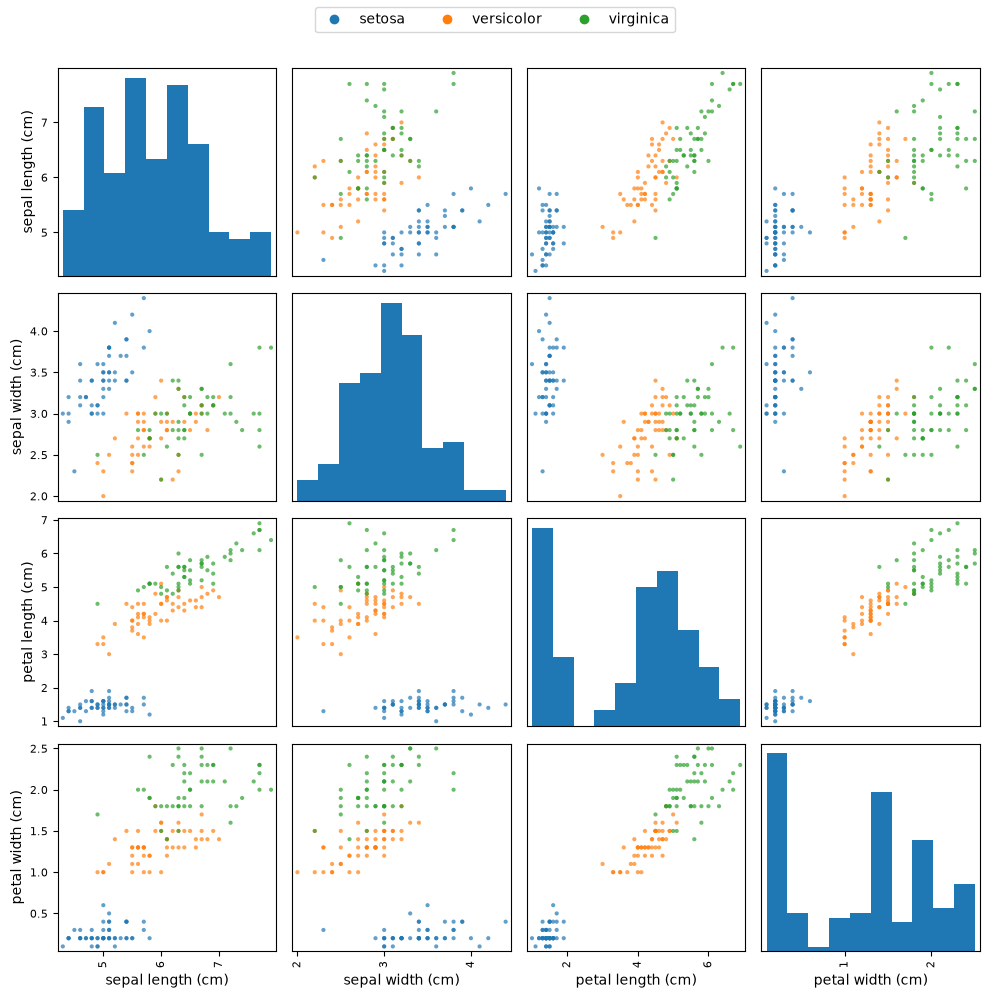

In [ ]:
species_colours = ListedColormap(plt.rcParams['axes.prop_cycle'].by_key()['color'][:len(names)])

axes = scatter_matrix(X, c=y, cmap=species_colours, figsize=(10, 10), diagonal='hist', alpha=.7)
fig = axes[0, 0].figure

handles = [
    Line2D([], [], marker='o', linestyle='', color=colour, label=species)
    for colour, species in zip(species_colours.colors, names)
]
fig.legend(handles=handles, loc='upper center', ncol=len(names))
fig.tight_layout(rect=(0, 0, 1, .95))
plt.show()

## Training a model
We want to train a Model that can allow classification of a flower, given the above mentioned parameters. Before we select a model, we first need to split the dataset into two parts:

1. Training
2. Testing

The training data will be used, as the name implies, to train the model. Once it is trained, we can use the testing data to estimate how well it predicts the species of flowers it has not seen during training.

There is no clear definition of the percentage of the data that should be used for either training or testing, but generally, the testing is lower than the training data. One possible split could be `70% training` and `30% testing`


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

Before we train our model, we should also scale the features. `KNN` compares distances between flowers, so features with larger scales could dominate these distances. We will use a `StandardScaler` from `scikit-learn`, which implements `z-scoring`: it subtracts the training mean and divides by the training standard deviation for each feature. This puts the features on a comparable scale, but does not make them equally useful for classification. Some other classifiers do not need this scaling. 

For the model, you can choose any Classifier of your choice, for this tutorial, we used `k-nearest neighbour (KNN)`. 

To make our lifes easier, we also use the pipeline functionality of `scikit-learn`, that allows fitting and scoring the data easy, without needing a lot of temporary variables.

Now we fit our scaler and model on the training data.

In [ ]:
baseline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal length (cm)','sepal width (cm)','petal length (cm)', 'petal width (cm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


The model is now fitted. We can check its performance by calling `.score` on the pipeline. For this classifier, the score is the accuracy: the fraction of flowers whose species was predicted correctly.

We calculate this for both parts of our dataset:

1. **Training accuracy:** How well does the model classify the flowers it was trained on?
2. **Test accuracy:** How well does the model classify flowers it has never seen during training?

The pipeline applies the scaling learned from the training data before making predictions. Calling `.score` does not train the model again.

In [ ]:
base_train_accuracy = baseline.score(X_train, y_train)
base_accuracy = baseline.score(X_test, y_test)

print(f'Train accuracy: {base_train_accuracy:.1%} ({round(base_train_accuracy * len(y_train))}/{len(y_train)} correct)')
print(f'Test accuracy:  {base_accuracy:.1%} ({round(base_accuracy * len(y_test))}/{len(y_test)} correct)')

Train accuracy: 98.1% (103/105 correct)
Test accuracy:  91.1% (41/45 correct)


The model performs well on both sets, although the training accuracy is higher than the test accuracy. This is common, as the model has already seen the training flowers. A much larger difference could be a sign of `overfitting`, where the model learns patterns that do not work as well for new data.

Our test set only contains 45 flowers, so one mistake changes the accuracy by about `2.2 percentage points`. Small differences should therefore be interpreted carefully.

We will use these scores as our `baseline`. Next, we want to see if the model can achieve similar accuracy with fewer features. For this, we will use `PCA`.

## Using fewer features
We have now trained a model using all four features. We want to see if we can reduce the number of features and still classify the flowers with similar performance.

For this, we use `Principal Component Analysis (PCA)`. PCA combines the original features into new features, technically called `principal components`. From this point on, we will call these new features `features` as well. They are combinations of the original measurements, rather than individual measurements such as petal length.

The first new feature describes the direction in which the scaled data varies the most. Each following feature describes a direction perpendicular to all the previous directions, keeping as much of the remaining variation as possible.

We can then keep only some of these features. However, PCA does not use the flower species, `y`, to find these directions. Keeping most of the variation does not necessarily mean keeping all the information needed for classification.

### Plotting the variation
Before we decide how many features to keep, we can check how much variation each feature describes. For this, we first scale the training data and fit `PCA` without limiting the number of features. This gives us all four features.

The bars show the variation explained by each feature. The line shows the `cumulative explained variance`, which adds up the variation as we keep more features. For example, the second point tells us how much variation the first two features keep together.

We only use the training data here. These percentages describe variation in the scaled measurements, rather than classification accuracy.

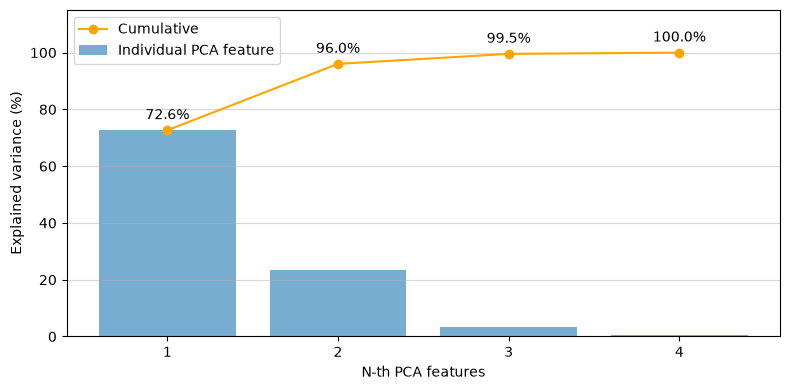

In [ ]:
variation_scaler = StandardScaler()
variation_train = variation_scaler.fit_transform(X_train)

pca_all = PCA()
pca_all.fit(variation_train)

explained_variance = pca_all.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
feature_numbers = np.arange(1, len(explained_variance) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(feature_numbers, explained_variance * 100, alpha=0.6, label='Individual PCA feature')
ax.plot(feature_numbers, cumulative_variance * 100, marker='o', color='orange', label='Cumulative')
for feature_number, cumulative in zip(feature_numbers, cumulative_variance):
    ax.annotate(f'{cumulative:.1%}', (feature_number, cumulative * 100), xytext=(0, 8), textcoords='offset points', ha='center')
ax.set(xlabel='N-th PCA features', ylabel='Explained variance (%)', xticks=feature_numbers, ylim=(0, 115))
ax.legend()
ax.grid(axis='y', alpha=.5)
plt.tight_layout()
plt.show()

### Fitting the pipeline
Looking at the variation plot, the first two PCA features already keep most of the variation. We therefore start by reducing our four original features to `2 PCA features` and check how well the classifier performs. We use the same scaler and classifier as before, and add `PCA` between them.

Calling `.fit` now first learns the scaling, then the PCA transformation, and finally fits the classifier on the transformed training data.

In [ ]:
pca_2_model = make_pipeline(
    StandardScaler(),
    PCA(n_components=2),
    KNeighborsClassifier(n_neighbors=5)
)
pca_2_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal length (cm)','sepal width (cm)','petal length (cm)', 'petal width (cm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### Checking the scores
The pipeline is now fitted. As we did before, we can call `.score` for both the training and testing data. The pipeline applies the fitted scaler and PCA transformation before passing the data to the classifier.

The variation kept by these two features can be read from the second point on the cumulative line in the variation plot above.

In [ ]:
pca_2_train_accuracy = pca_2_model.score(X_train, y_train)
pca_2_accuracy = pca_2_model.score(X_test, y_test)

pca_step = pca_2_model.named_steps['pca']

print(f'Train accuracy: {pca_2_train_accuracy:.1%} ({round(pca_2_train_accuracy * len(y_train))}/{len(y_train)} correct)')
print(f'Test accuracy:  {pca_2_accuracy:.1%} ({round(pca_2_accuracy * len(y_test))}/{len(y_test)} correct)')

Train accuracy: 94.3% (99/105 correct)
Test accuracy:  91.1% (41/45 correct)


The test accuracy is still `91.1%`, the same as our baseline, even though the classifier now uses only two features instead of four. The training accuracy has decreased from `98.1%` to `94.3%`, but the number of correctly predicted test flowers has stayed the same.

We have therefore kept the same test accuracy for this split with half as many inputs. Storing two feature values per flower instead of four takes half the space for the transformed feature values, assuming the same numeric format. We still need the original measurements and the fitted scaler and PCA to transform new flowers.

### Plotting the features
As we now have two features, we can plot both of them against one another. Unlike the first plot, each axis is now a combination of the original measurements, rather than a single measurement such as petal length.

We first transform the training data using the scaler and PCA that we already fitted. We use `.transform` here, as we do not want to fit them again. We then use the species labels to give each flower its colour. These labels are only used for the plot; PCA did not use them to learn the features.

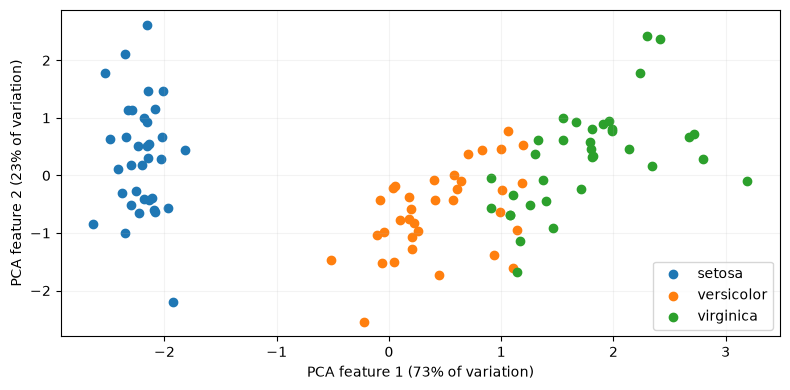

In [ ]:
scaled_train = pca_2_model.named_steps['standardscaler'].transform(X_train)
points_2d = pca_step.transform(scaled_train)

fig, ax = plt.subplots(figsize=(8, 4))
for i, species in enumerate(names):
    mask = y_train.to_numpy() == i
    ax.scatter(points_2d[mask, 0], points_2d[mask, 1], label=species)
ax.set(xlabel=f'PCA feature 1 ({pca_step.explained_variance_ratio_[0]:.0%} of variation)',
       ylabel=f'PCA feature 2 ({pca_step.explained_variance_ratio_[1]:.0%} of variation)')
ax.legend()
ax.grid(alpha=.15)
plt.tight_layout()
plt.show()

### Using three features
In the variation plot, the third bar shows how much extra variation the third PCA feature describes. The cumulative line rises closer to `100%` when we include it. We can therefore also try `3 PCA features` to see whether keeping this extra variation helps classification, while still using one fewer feature than our baseline.

We create another pipeline and fit it on the same training data. We keep the classifier settings unchanged, such that we can compare the effect of changing the number of features.

In [ ]:
pca_3_model = make_pipeline(
    StandardScaler(),
    PCA(n_components=3),
    KNeighborsClassifier(n_neighbors=5)
)
pca_3_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal length (cm)','sepal width (cm)','petal length (cm)', 'petal width (cm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Now we calculate the training and testing scores again. To compare how much variation is kept with three features instead of two, we can look back at the cumulative line in the variation plot.

In [ ]:
pca_3_train_accuracy = pca_3_model.score(X_train, y_train)
pca_3_accuracy = pca_3_model.score(X_test, y_test)

print(f'Train accuracy: {pca_3_train_accuracy:.1%} ({round(pca_3_train_accuracy * len(y_train))}/{len(y_train)} correct)')
print(f'Test accuracy:  {pca_3_accuracy:.1%} ({round(pca_3_accuracy * len(y_test))}/{len(y_test)} correct)')

Train accuracy: 98.1% (103/105 correct)
Test accuracy:  93.3% (42/45 correct)


## Comparing the models
We now have three fitted pipelines. All of them use the same training and testing data and the same `KNN` settings. The difference is the features that the classifier receives:

1. All `4 original features`
2. `2 PCA features`
3. `3 PCA features`

We first put the training and testing scores next to each other. As before, we look at both scores to see how well each model predicts the training examples and the flowers it has not seen.

In [ ]:
methods = ['No PCA', 'PCA: 2 features', 'PCA: 3 features']
train_accuracies = [base_train_accuracy, pca_2_train_accuracy, pca_3_train_accuracy]
accuracies = [base_accuracy, pca_2_accuracy, pca_3_accuracy]
features = [4, 2, 3]

for label, train_score, test_score in zip(methods, train_accuracies, accuracies):
    print(f'{label:16s} | Train accuracy: {train_score:.1%} | Test accuracy: {test_score:.1%}')

No PCA           | Train accuracy: 98.1% | Test accuracy: 91.1%
PCA: 2 features  | Train accuracy: 94.3% | Test accuracy: 91.1%
PCA: 3 features  | Train accuracy: 98.1% | Test accuracy: 93.3%


### What does this tell us?
For this split, using two features gives the same test accuracy as using all four features. Using three features gives a slightly higher test accuracy. The difference between `91.1%` and `93.3%` is only one correctly predicted flower out of our 45 test examples.

The variation plot showed that two PCA features already keep most of the variation, and that the third adds a smaller amount. Our scores show how these choices affect classification for this split. A higher point on the cumulative line does not guarantee better predictions, as the plot describes variation rather than how well the species can be separated. We might still remove information that is useful for distinguishing the species.

We also still need all four original measurements to calculate the features for a new flower. PCA reduces the number of inputs passed to the classifier, rather than the number of measurements we need to collect.

## Optional: Checking the result with cross-validation
So far, our comparison uses one training and testing split. A different split might give different results, especially with a small dataset such as Iris.

We can use `cross-validation` to compare the pipelines within the training data. We split the training data into five parts, called `folds`. For each run, four folds are used for fitting and the remaining fold is used for validation. This is repeated until every fold has been used for validation once.

We use `StratifiedKFold` to keep the proportion of flower species similar in each fold. Setting `random_state=42` makes the shuffled folds reproducible.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Now we repeat the comparison for our three pipelines. We build the steps in a list, so we can add PCA only when it is needed. `make_pipeline(*steps)` creates a pipeline from that list.

`cross_val_score` fits a fresh pipeline for each fold. This means the scaler and PCA are learned only from that fold's fitting data, without using its validation examples. We use `X_train` and `y_train` here, so our test set is left out.

We print the mean validation accuracy and the individual fold scores. The fold scores let us see how much the result changes depending on which flowers are used for validation.

In [ ]:
for label, n_features in [('No PCA', None), ('2 features', 2), ('3 features', 3)]:
    steps = [StandardScaler()]
    if n_features is not None:
        steps.append(PCA(n_components=n_features))
    steps.append(KNeighborsClassifier(n_neighbors=5))
    model = make_pipeline(*steps)
    scores = cross_val_score(model, X_train, y_train, cv=cv)
    print(f'{label:16s}  mean CV accuracy: {scores.mean():.1%}  (scores: {np.round(scores, 2)})')

No PCA            mean CV accuracy: 93.3%  (scores: [0.86 1.   0.95 0.95 0.9 ])
2 features        mean CV accuracy: 89.5%  (scores: [0.81 0.9  0.9  0.9  0.95])
3 features        mean CV accuracy: 95.2%  (scores: [0.86 1.   1.   0.95 0.95])


The mean scores give us another way to compare the pipelines, and the individual scores show why one favourable split is not enough to guarantee better predictions. Each validation fold is also small, so a few mistakes can change its accuracy considerably.

For a new model, we would use these training-only validation results to choose the number of features, fit the chosen pipeline on all the training data, and then evaluate it on the test set. In this tutorial we have already looked at several test scores to demonstrate the comparison, so they should be treated as examples rather than a final evaluation of a tuned model.

PCA allows us to describe the flowers using fewer features while keeping much of the variation. Whether this helps the classifier needs to be checked for the dataset and model we are using.